# Lab 08 — Pretrained Transformers và ALBERT Fine-Tuning

IMDb sentiment classification; checkpoint `albert/albert-base-v2`.

In [1]:
from pathlib import Path
import os, sys
LAB_DIR = Path.cwd().resolve()
if LAB_DIR.name != 'lab08':
    LAB_DIR = LAB_DIR / 'labs' / 'lab08'
ROOT = LAB_DIR.parents[1]
os.environ['HF_HOME'] = str(ROOT / 'models' / 'huggingface')
os.environ['HF_HUB_DISABLE_XET'] = '1'
sys.path.insert(0, str(LAB_DIR))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from pretrained_classification import *
seed_everything()
pd.set_option('display.max_colwidth', 160)
tokenizer = get_tokenizer()
print('Model:', MODEL_ID, '| Revision:', REVISION)
print(hardware_info())

D:\Project\NLP-2025\NLP-Labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: albert/albert-base-v2 | Revision: 8e2f239c5f8a2c0f253781ca60135db913e5c80c
{'device': 'cpu', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.14.1+cpu', 'threads': 4, 'gpu': None}


## 11. Prediction trước experiment

Ba prediction được ghi trước khi chạy trong `prediction.md`. Prediction 1: pretrained có thể tốt hơn from-scratch; Prediction 2: frozen có thể kém fine-tuning; Prediction 3: pretrained có thể giảm ít hơn khi training data ít.

## 12–13. Dataset và classification head

Dùng cùng tokenizer ALBERT cho cả hai model để giữ cách cắt token giống nhau. Scratch là một block 128 chiều, 4 heads, FFN 256 lấy output `[CLS]`; ALBERT dùng pooled `[CLS]` 768 chiều qua Linear 2 nhãn. Hai kiến trúc khác nhau nên thí nghiệm so sánh hai pipeline, không tách riêng hoàn toàn tác động của pretraining.

In [2]:
splits = load_splits()
display(pd.DataFrame([{'split': name, 'samples': len(frame),
                       'negative': int((frame.label == 0).sum()),
                       'positive': int((frame.label == 1).sum())}
                      for name, frame in splits.items()]))
print('Split SHA256:', split_fingerprints(splits))
print('Batch:', BATCH_SIZE, '| Epochs:', EPOCHS, '| Seed:', SEED)
print('Max length includes [CLS] and [SEP]; labels: 0 negative, 1 positive')
print('AdamW: scratch/head lr=0.001; full fine-tuning lr=0.00002; weight_decay=0.01')
REUSE_CHECKPOINTS = True  # Set False to train every configuration again.
runs = {}
base_model = None
def run(kind='finetuned', fraction=1.0, length=64):
    global base_model
    key = (kind, fraction, length)
    if key not in runs:
        restored = restore_experiment(splits, tokenizer, kind, fraction, length,
                                      keep_model=key == ('finetuned', 1.0, 64)) if REUSE_CHECKPOINTS else None
        model, result = restored if restored is not None else train_experiment(splits, tokenizer, kind, fraction, length)
        runs[key] = result
        if key == ('finetuned', 1.0, 64):
            base_model = model
        else:
            del model
    return runs[key]
def rows_table(results):
    return pd.DataFrame([r['row'] for r in results])

,split,samples,negative,positive
0,train,600,300,300
1,validation,200,100,100
2,test,200,100,100


Split SHA256: {'train': 'aca571c7c8bd97023d12ce7857665b1b2147003d71eb00989e99045262ac51e1', 'validation': '09ef420e77b431e5bf2c6d045bf4d9d8883b1c53e0531c8d5d7ce1a65217d65d', 'test': '9b22f071d034fc092f366aa0a44c57f370bd9e037d1376c09b750f8b1486f39b'}
Batch: 8 | Epochs: 2 | Seed: 42
Max length includes [CLS] and [SEP]; labels: 0 negative, 1 positive
AdamW: scratch/head lr=0.001; full fine-tuning lr=0.00002; weight_decay=0.01


## 14. Experiment 1 — Pretrained vs From Scratch

In [3]:
pretrained = run()
scratch = run('scratch')
display(rows_table([scratch, pretrained])[['model', 'accuracy', 'precision', 'recall', 'f1',
                                         'training_time_sec', 'parameters', 'validation_f1']])

Restored finetuned_1.0_64.pt; original training time=657.79s


Restored scratch_1.0_64.pt; original training time=16.61s


,model,accuracy,precision,recall,f1,training_time_sec,parameters,validation_f1
0,scratch,0.540,0.541667,0.52,0.530612,16.606287,3972738,0.582011
1,finetuned,0.785,0.771429,0.81,0.790244,657.788910,11685122,0.790000


**Trả lời:** ALBERT fine-tuned đạt accuracy = 0.7850, F1 = 0.7902; scratch đạt 0.5400 và 0.5306. Kết quả phù hợp Prediction 1 trong lần chạy này.

Scratch học representation từ trọng số ngẫu nhiên; ALBERT bắt đầu từ representation pretrained rồi điều chỉnh cho IMDb. Pretraining có thể giảm nhu cầu dữ liệu downstream, nhưng bảng này chưa đủ đo chính xác cần bao nhiêu mẫu.

Training time lần lượt là 657.79 và 16.61 giây; số tham số là 11,685,122 và 3,972,738. ALBERT tốt hơn nhưng tốn thời gian hơn ở cấu hình này. Hai kiến trúc và learning rate khác nhau, nên không quy toàn bộ chênh lệch cho pretraining.

## 15. Experiment 2 — Feature Extraction vs Fine-Tuning

In [4]:
frozen = run('frozen')
display(rows_table([frozen, pretrained])[['model', 'trainable_parameters', 'parameters',
                                         'accuracy', 'f1', 'training_time_sec']])

Restored frozen_1.0_64.pt; original training time=52.39s


,model,trainable_parameters,parameters,accuracy,f1,training_time_sec
0,frozen,1538,11685122,0.525,0.652015,52.393224
1,finetuned,11685122,11685122,0.785,0.790244,657.788910


**Trả lời:** Encoder trainable: **No** ở frozen, **Yes** ở full fine-tuning. Frozen đạt F1 = 0.6520, còn full fine-tuning đạt 0.7902. Chỉ 1,538 tham số của head được train ở frozen, so với 11,685,122 khi fine-tune toàn bộ. Kết quả phù hợp Prediction 2 ở lần chạy này.

Frozen vẫn phân loại được vì head học từ các feature đã có trong pretrained encoder. Fine-tuning còn điều chỉnh các feature cho sentiment IMDb nên có thể tốt hơn. Frozen tốn 52.39 giây, đã tính trích xuất train/validation features. Đây là so sánh hai chế độ với learning rate phù hợp riêng, không phải ablation chỉ đổi duy nhất một biến.

## 16. Experiment 3 — Amount of Training Data

Restored scratch_0.1_64.pt; original training time=0.84s


Restored scratch_0.25_64.pt; original training time=1.78s


Restored scratch_0.5_64.pt; original training time=3.42s


finetuned fraction=0.1 length=64 epoch=1 val_F1=0.5882


finetuned fraction=0.1 length=64 epoch=2 val_F1=0.5143


finetuned fraction=0.25 length=64 epoch=1 val_F1=0.7345


finetuned fraction=0.25 length=64 epoch=2 val_F1=0.5970


finetuned fraction=0.5 length=64 epoch=1 val_F1=0.7322


finetuned fraction=0.5 length=64 epoch=2 val_F1=0.7122


,model,train_fraction,train_samples,accuracy,f1,validation_f1
0,scratch,0.10,60,0.505,0.668896,0.666667
1,scratch,0.25,150,0.545,0.260163,0.216667
2,scratch,0.50,300,0.605,0.666667,0.707317
3,scratch,1.00,600,0.540,0.530612,0.582011
4,finetuned,0.10,60,0.600,0.655172,0.588235
5,finetuned,0.25,150,0.630,0.678261,0.734513
6,finetuned,0.50,300,0.650,0.615385,0.732240
7,finetuned,1.00,600,0.785,0.790244,0.790000


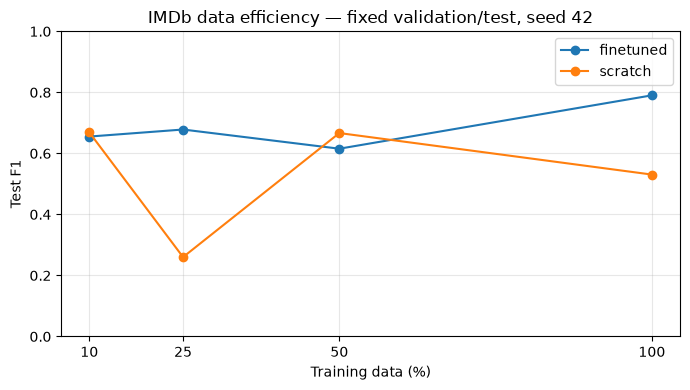

In [5]:
fractions = [0.1, 0.25, 0.5, 1.0]
data_runs = [run(kind, fraction) for kind in ['scratch', 'finetuned'] for fraction in fractions]
data_table = rows_table(data_runs)
display(data_table[['model', 'train_fraction', 'train_samples', 'accuracy', 'f1', 'validation_f1']])
fig, ax = plt.subplots(figsize=(7, 4))
for kind, group in data_table.groupby('model'):
    ax.plot(group.train_fraction * 100, group.f1, marker='o', label=kind)
ax.set(xlabel='Training data (%)', ylabel='Test F1', xticks=[10, 25, 50, 100], ylim=(0, 1),
       title='IMDb data efficiency — fixed validation/test, seed 42')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(LAB_DIR / 'data_efficiency.png', dpi=160)
plt.show()

**Trả lời:** F1 theo 10/25/50/100% train:

- Scratch: 10%: 0.6689, 25%: 0.2602, 50%: 0.6667, 100%: 0.5306.
- ALBERT fine-tuned: 10%: 0.6552, 25%: 0.6783, 50%: 0.6154, 100%: 0.7902.

Các điểm không nhất thiết tăng đều. Ở 10%, scratch có accuracy = 0.5050, precision = 0.5025, recall = 1.0000; model dự đoán gần như toàn positive. Vì vậy F1 ở điểm này không chứng minh model học tốt hơn khi có ít dữ liệu.

Chênh lệch F1 từ 100% xuống 10% là 0.1351 với ALBERT và -0.1383 với scratch. ALBERT có accuracy cao hơn scratch ở cả bốn mức dữ liệu, nhưng mức giảm F1 quan sát được không ủng hộ Prediction 3 rằng pretrained giảm ít hơn khi còn 10%. Không sửa lại prediction sau khi thấy kết quả. Mỗi mức chỉ chạy một seed và hai epoch, nên chưa đủ kết luận tổng quát về data efficiency.

## 17. Experiment 4 — Maximum Sequence Length

Mỗi length bắt đầu lại từ cùng pretrained checkpoint và seed, không tiếp tục từ run trước. Peak CPU memory là RSS của toàn tiến trình được lấy mẫu 50 ms trong training, có cả Python và bộ nhớ allocator giữ lại; không phải phép đo memory riêng của tensor attention.

In [6]:
length_runs = [run(length=length) for length in [64, 128, 256]]
display(rows_table(length_runs)[['max_length', 'accuracy', 'f1', 'training_time_sec',
                                 'peak_memory_mib', 'memory_kind']])

finetuned fraction=1.0 length=128 epoch=1 val_F1=0.4889


finetuned fraction=1.0 length=128 epoch=2 val_F1=0.8168


finetuned fraction=1.0 length=256 epoch=1 val_F1=0.3548


finetuned fraction=1.0 length=256 epoch=2 val_F1=0.8976


,max_length,accuracy,f1,training_time_sec,peak_memory_mib,memory_kind
0,64,0.785,0.790244,657.788910,770.308594,process RSS
1,128,0.870,0.864583,446.020695,1567.703125,process RSS
2,256,0.895,0.901408,1482.895796,2272.714844,process RSS


**Trả lời:** T=64: F1=0.7902, time=657.79s, peak RSS=770.3 MiB; T=128: F1=0.8646, time=446.02s, peak RSS=1567.7 MiB; T=256: F1=0.9014, time=1482.90s, peak RSS=2272.7 MiB.

Trong lần chạy này F1 tăng ở cả ba mức, nhưng không đủ kết luận tăng length luôn tốt hơn. Full attention có ma trận T×T, nên tăng từ 64 lên 256 làm số phần tử score mỗi head tăng 16 lần. Thời gian toàn model còn phụ thuộc FFN, backward và phần cứng; không nhất thiết tăng đúng 16 lần.

Wall-clock time ở T=128 thấp hơn T=64 trong lần đo này; các run chưa được benchmark lặp với tải hệ thống được kiểm soát, nên không suy ra chuỗi dài hơn có chi phí thuật toán thấp hơn. RSS là memory toàn tiến trình và có ảnh hưởng của allocator/các run trước.

## 18. Experiment 5 — Domain Shift

Train và chọn checkpoint chỉ bằng IMDb train/validation. Amazon product reviews từ UCI chỉ dùng đánh giá, không cập nhật model. Domain và độ dài/style đều thay đổi, nên không tách riêng được từng ảnh hưởng.

In [7]:
amazon = load_amazon(splits)
amazon_result = evaluate(base_model, loader(encoded_dataset(amazon, tokenizer, 64)))
domain_table = pd.DataFrame([{'domain': 'IMDb movie reviews', 'samples': len(splits['test']),
                             **pretrained['test']['metrics']},
                            {'domain': 'Amazon product reviews', 'samples': len(amazon),
                             **amazon_result['metrics']}])
display(domain_table)
print('Amazon class counts:', amazon.label.value_counts().to_dict())

,domain,samples,accuracy,precision,recall,f1
0,IMDb movie reviews,200,0.78500,0.771429,0.810000,0.790244
1,Amazon product reviews,990,0.80303,0.731366,0.955375,0.828496


Amazon class counts: {0: 497, 1: 493}


**Trả lời:** Model train trên IMDb đạt F1 = 0.7902 trên IMDb test và 0.8285 trên 990 review Amazon, với accuracy tương ứng 0.7850 và 0.8030.

Ở tập Amazon này, F1 cao hơn IMDb nên không quan sát thấy suy giảm performance. Domain, độ dài, style và mức rõ ràng của sentiment đều có thể ảnh hưởng; thí nghiệm chưa tách riêng được chúng. Kết quả không có nghĩa pretrained model đã hiểu mọi domain. Không dùng test Amazon để chọn model hoặc điều chỉnh hyperparameter.

## 19. Application — Sentiment Classification

,accuracy,precision,recall,f1
0,0.785,0.771429,0.81,0.790244


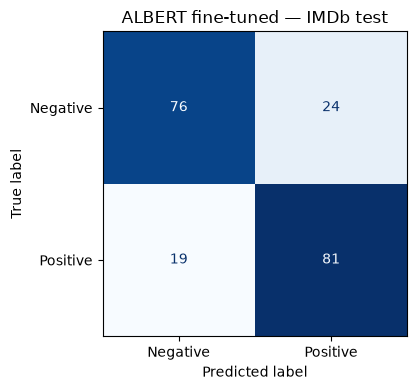

In [8]:
test = pretrained['test']
display(pd.DataFrame([test['metrics']]))
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(test['truth'], test['prediction'], labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('ALBERT fine-tuned — IMDb test')
fig.tight_layout(); fig.savefig(LAB_DIR / 'confusion_matrix.png', dpi=160)
plt.show()

**Nhận xét:** Confusion matrix có TN = 76, FP = 24, FN = 19, TP = 81. Precision positive = 0.7714, recall = 0.8100, F1 = 0.7902. Các metric dùng cùng nhãn và cùng 200 review test; không chỉ báo cáo accuracy.

## 20. Error Analysis

Chọn ba false positive, ba false negative và hai prediction sai có confidence cao nhất. Hai mẫu cuối có thể trùng sáu mẫu đầu; bảng ghi rõ nhóm. Ngưỡng high confidence được đặt trước là 0.90.

In [9]:
truth, prediction, confidence = test['truth'], test['prediction'], test['confidence']
fp = np.flatnonzero((truth == 0) & (prediction == 1))[:3]
fn = np.flatnonzero((truth == 1) & (prediction == 0))[:3]
wrong = np.flatnonzero(truth != prediction)
confident_wrong = wrong[np.argsort(-confidence[wrong])[:2]]
error_rows = []
for group, indices in [('FP', fp), ('FN', fn), ('Most confident wrong', confident_wrong)]:
    for i in indices:
        raw = splits['test'].iloc[i].text
        ids = tokenizer(raw, truncation=True, max_length=64)['input_ids']
        error_rows.append({'group': group, 'test_index': int(i), 'text': raw,
                           'visible_text': tokenizer.decode(ids, skip_special_tokens=True),
                           'true': int(truth[i]), 'pred': int(prediction[i]),
                           'confidence': float(confidence[i]),
                           'p_positive': float(test['probabilities'][i, 1]),
                           'full_tokens': len(tokenizer(raw)['input_ids']),
                           'truncated': len(tokenizer(raw)['input_ids']) > 64})
error_table = pd.DataFrame(error_rows)
display(error_table[['group', 'test_index', 'true', 'pred', 'confidence', 'truncated', 'visible_text']])
assert len(fp) == 3 and len(fn) == 3
print('Wrong predictions with confidence >= 0.90:', int(((truth != prediction) & (confidence >= 0.90)).sum()))

,group,test_index,true,pred,confidence,truncated,visible_text
0,FP,1,0,1,0.870291,True,"this film, by oscar petersson, is unique. its uniqueness doesn't lie in the story, since many a half brained hollywood production has served us comparably m..."
1,FP,10,0,1,0.856027,True,"this movie had good intentions and a good story to work with. the director and screenwriter of this movie failed miserably and created a dull, boring filmst..."
2,FP,16,0,1,0.889306,True,"i first didn't want to watch this film, for the trailer gave the impression of a common and too expected film...but as i recently had the pleasure to discov..."
3,FN,4,1,0,0.826279,True,"""nothin'. there ain't nothing' in room 237. but you ain't got no business going' in there anyway. so stay out. you understand? stay out."" br /br /never has ..."
4,FN,15,1,0,0.859876,True,"i guess when ""beat street"" made a national appearance, ""flashdance"" came at the same time. the problem with ""flashdance"" is that there was only one break da..."
5,FN,44,1,0,0.830665,True,"....rather well done, actually--attack the evil villains in their lair, stop a little big horn style ambush, save the day via the waterboys' bugling, works ..."
6,Most confident wrong,85,0,1,0.901781,True,this hodge-podge adapted from a gore vidal novel (actually one of the great american writers) makes the magic christian and valley of the dolls look like fe...
7,Most confident wrong,100,0,1,0.898037,True,"this is high grade cheese fare of b movie kung fu flicks. bruce ""wannabe"" lee is played by bruce li...i think. of course, let's show quick clips of bruce an..."


Wrong predictions with confidence >= 0.90: 1


**Nhận xét:** Bảng có ba FP, ba FN và hai prediction sai có confidence cao nhất; 1/2 mẫu cuối đạt ngưỡng 0.90. Các mẫu có thể trùng nhóm. `visible_text` là input đã được decode và bỏ special tokens, giúp đối chiếu nội dung được giữ lại với nội dung bị truncation. Bảng Error type/Hypothesis và phân tích cụ thể nằm trong `error_analysis.md`; không xem giả thuyết là nguyên nhân đã được chứng minh.

## 21. Confidence Analysis

Low: [0.50, 0.70), Medium: [0.70, 0.90), High: [0.90, 1.00]. Confidence là max softmax, không mặc định là xác suất đúng đã được hiệu chỉnh.

,samples,accuracy,mean_confidence
group,,,
Low,26,0.653846,0.608459
Medium,156,0.788462,0.845797
High,18,0.944444,0.907066


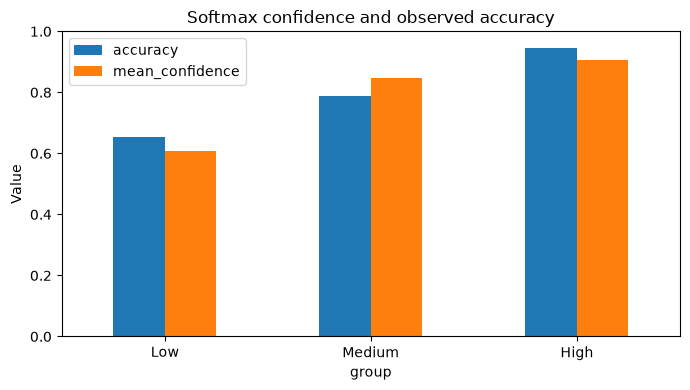

In [10]:
groups = np.where(confidence >= 0.90, 'High', np.where(confidence >= 0.70, 'Medium', 'Low'))
confidence_table = pd.DataFrame({'group': groups, 'confidence': confidence,
                                'correct': truth == prediction}).groupby('group', observed=True).agg(
                                    samples=('correct', 'size'), accuracy=('correct', 'mean'),
                                    mean_confidence=('confidence', 'mean')).reindex(['Low', 'Medium', 'High'])
display(confidence_table)
fig, ax = plt.subplots(figsize=(7, 4))
confidence_table[['accuracy', 'mean_confidence']].plot.bar(ax=ax, rot=0)
ax.set(ylim=(0, 1), ylabel='Value', title='Softmax confidence and observed accuracy')
fig.tight_layout(); fig.savefig(LAB_DIR / 'confidence_analysis.png', dpi=160)
plt.show()

**Trả lời:** Nhóm high confidence có 18 mẫu; accuracy quan sát là 0.9444 và mean confidence là 0.9071.

Confidence cao không đảm bảo prediction đúng: các mẫu sai tự tin đã được chỉ ra ở phần trên. Chia bin chỉ là kiểm tra mô tả trên test set, chưa phải hiệu chỉnh xác suất hay bằng chứng model đã calibrated.

## 22–23. Controlled analysis và reproducibility

Các bảng trên kiểm soát split, seed, batch size và số epoch. Fine-tuning dùng learning rate thấp hơn scratch/head vì encoder đã pretrained. Best checkpoint được chọn bằng validation F1, không chọn bằng test. Thời gian gồm training và validation; frozen gồm trích xuất train/validation features, không gồm download, tokenization và đánh giá test. Các cấu hình trùng nhau chỉ train một lần.

In [11]:
result_table = pd.DataFrame([result['row'] for result in runs.values()])
result_table['checkpoint'] = np.where(result_table.model == 'scratch', 'random-small-transformer', MODEL_ID)
result_table['revision'] = np.where(result_table.model == 'scratch', '', REVISION)
result_table['device'] = str(DEVICE)
result_table.round(6).to_csv(LAB_DIR / 'results.csv', index=False)
display(result_table[['model', 'train_fraction', 'max_length', 'accuracy', 'precision', 'recall', 'f1']])
import json
summary = {'hardware': hardware_info(), 'fingerprints': split_fingerprints(splits),
           'results': result_table.to_dict('records'), 'domain': domain_table.to_dict('records'),
           'confusion_matrix': cm.tolist(), 'errors': error_rows,
           'confidence': confidence_table.reset_index().to_dict('records'),
           'histories': {str(key): result['history'] for key, result in runs.items()}}
summary_path = ROOT / 'checkpoints' / 'lab08' / 'summary.json'
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Saved results.csv; checkpoint:', MODEL_ID, REVISION)

,model,train_fraction,max_length,accuracy,precision,recall,f1
0,finetuned,1.00,64,0.785,0.771429,0.81,0.790244
1,scratch,1.00,64,0.540,0.541667,0.52,0.530612
2,frozen,1.00,64,0.525,0.514451,0.89,0.652015
3,scratch,0.10,64,0.505,0.502513,1.00,0.668896
4,scratch,0.25,64,0.545,0.695652,0.16,0.260163
5,scratch,0.50,64,0.605,0.576642,0.79,0.666667
6,finetuned,0.10,64,0.600,0.575758,0.76,0.655172
7,finetuned,0.25,64,0.630,0.600000,0.78,0.678261
8,finetuned,0.50,64,0.650,0.682927,0.56,0.615385
9,finetuned,1.00,128,0.870,0.902174,0.83,0.864583


Saved results.csv; checkpoint: albert/albert-base-v2 8e2f239c5f8a2c0f253781ca60135db913e5c80c


## 27. Individual Learning Check

1. Pretraining học representation từ corpus lớn; fine-tuning điều chỉnh model cho task cụ thể.
2. MLM che một số token rồi dự đoán chúng bằng context còn lại.
3. Tokenizer chuyển text thành token IDs đúng vocabulary model đã học.
4. Subword cho phép biểu diễn nhiều từ bằng các mảnh nhỏ, giảm phụ thuộc vào vocabulary gồm toàn từ.
5. `[CLS]` thường được dùng làm representation của sequence rồi đưa vào head phân loại.
6. Attention mask phân biệt token thật và padding.
7. Frozen encoder giữ nguyên trọng số; chỉ head được train.
8. Full fine-tuning cập nhật encoder và classification head; một số cách chỉ cập nhật một phần.
9. Dataset downstream nhỏ vẫn có thể dùng các feature từ pretraining.
10. Pretrained model vẫn có thể bị domain shift.
11. Full attention so sánh mọi cặp token, nên số phần tử scores tăng theo T².
12. Confidence cao vẫn có thể dự đoán sai; phải đối chiếu nhãn và kiểm tra calibration.

## 28. Câu hỏi bắt buộc

Sáu câu trả lời dựa trên các bảng thực nghiệm được ghi ở cuối `error_analysis.md`.

## 29–30. Reflection và liên hệ Lab 09

Reflection 300–500 từ nằm trong `reflection.md`. Classification tạo một nhãn cho cả review; NER ở Lab 09 cần nhãn cho từng token hoặc span, ví dụ `Barack Obama → PERSON`, `Paris → LOCATION`.

## AI assistance statement

Chi tiết được ghi trong `README.md`.